In [2]:
import sys; sys.path.insert(0, '../..')
from paths import CODE
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

from sciplotlib import style as spstyle
from sciplotlib import polish as sppolish


In [3]:
# save_root='/home/wx2203/Weihao/code_publish/admin-figures/figures/figure-1/'

In [4]:
Hb_spec = scipy.io.loadmat('./Spectra/Hb_spectra.mat')
jrgeco_spec = pd.read_csv('./Spectra/jrgeco1a_fpbase_spectra.csv')
gcamp_spec = pd.read_csv('./Spectra/gcamp6f_fpbase_spectra.csv')
filters_spec = pd.read_csv('./Spectra/spectrometer.csv')

In [5]:
filters_spec.keys()

Index(['wavelength ', 'blue_ex', 'blue_raw', 'green_ex', 'green_raw',
       'lime_ex', 'lime_raw', 'red_ex', 'em_jrgeco_filter_under blue',
       'em_jrgeco_filter_under green', 'em_jrgeco_filter_under lime',
       'em_jrgeco_filter_under red', 'em_525_50_under_blue',
       'dv2_shorter_wl_under_white_led', 'dv2_longer_wl_under_white_led',
       'Unnamed: 15'],
      dtype='object')

In [6]:
for i_column,column in enumerate(filters_spec.columns):
    # print(i_column,column)
    if i_column>0 and i_column<15:
        filters_spec[column]=normalize(filters_spec[column])

In [7]:
for i_column,column in enumerate(filters_spec.columns):
    print(column)

wavelength 
blue_ex
blue_raw
green_ex
green_raw
lime_ex
lime_raw
red_ex
em_jrgeco_filter_under blue
em_jrgeco_filter_under green
em_jrgeco_filter_under lime
em_jrgeco_filter_under red
em_525_50_under_blue
dv2_shorter_wl_under_white_led
dv2_longer_wl_under_white_led
Unnamed: 15


In [9]:
lambdaHb=np.squeeze(Hb_spec['lambda'])
Hb02=np.squeeze(Hb_spec['Hb02'])
Hb=np.squeeze(Hb_spec['Hb'])

In [19]:
index_hb = np.logical_and(lambdaHb>500,lambdaHb<650)
index_jrgeco = np.logical_and(jrgeco_spec['wavelength']>500,jrgeco_spec['wavelength']<650)
index_gcamp = np.logical_and(gcamp_spec['wavelength']>500,gcamp_spec['wavelength']<650)
index_filters = np.logical_and(filters_spec['wavelength ']>500,filters_spec['wavelength ']<650)


In [15]:
filters_spec.keys()

Index(['wavelength ', 'blue_ex', 'blue_raw', 'green_ex', 'green_raw',
       'lime_ex', 'lime_raw', 'red_ex', 'em_jrgeco_filter_under blue',
       'em_jrgeco_filter_under green', 'em_jrgeco_filter_under lime',
       'em_jrgeco_filter_under red', 'em_525_50_under_blue',
       'dv2_shorter_wl_under_white_led', 'dv2_longer_wl_under_white_led',
       'Unnamed: 15'],
      dtype='object')

In [16]:
def find_start_stop_wavelengths(which_filter):
    trim_spec = filters_spec.loc[index_filters]
    ind_start=start_stop(filters_spec.loc[index_filters,which_filter]>0.6,True)[0,0]
    ind_stop = start_stop(filters_spec.loc[index_filters,which_filter]>0.6,True)[0,1]
    wl_start = np.squeeze(trim_spec['wavelength '].iloc[ind_start])
    wl_stop = np.squeeze(trim_spec['wavelength '].iloc[ind_stop])
    return wl_start,wl_stop

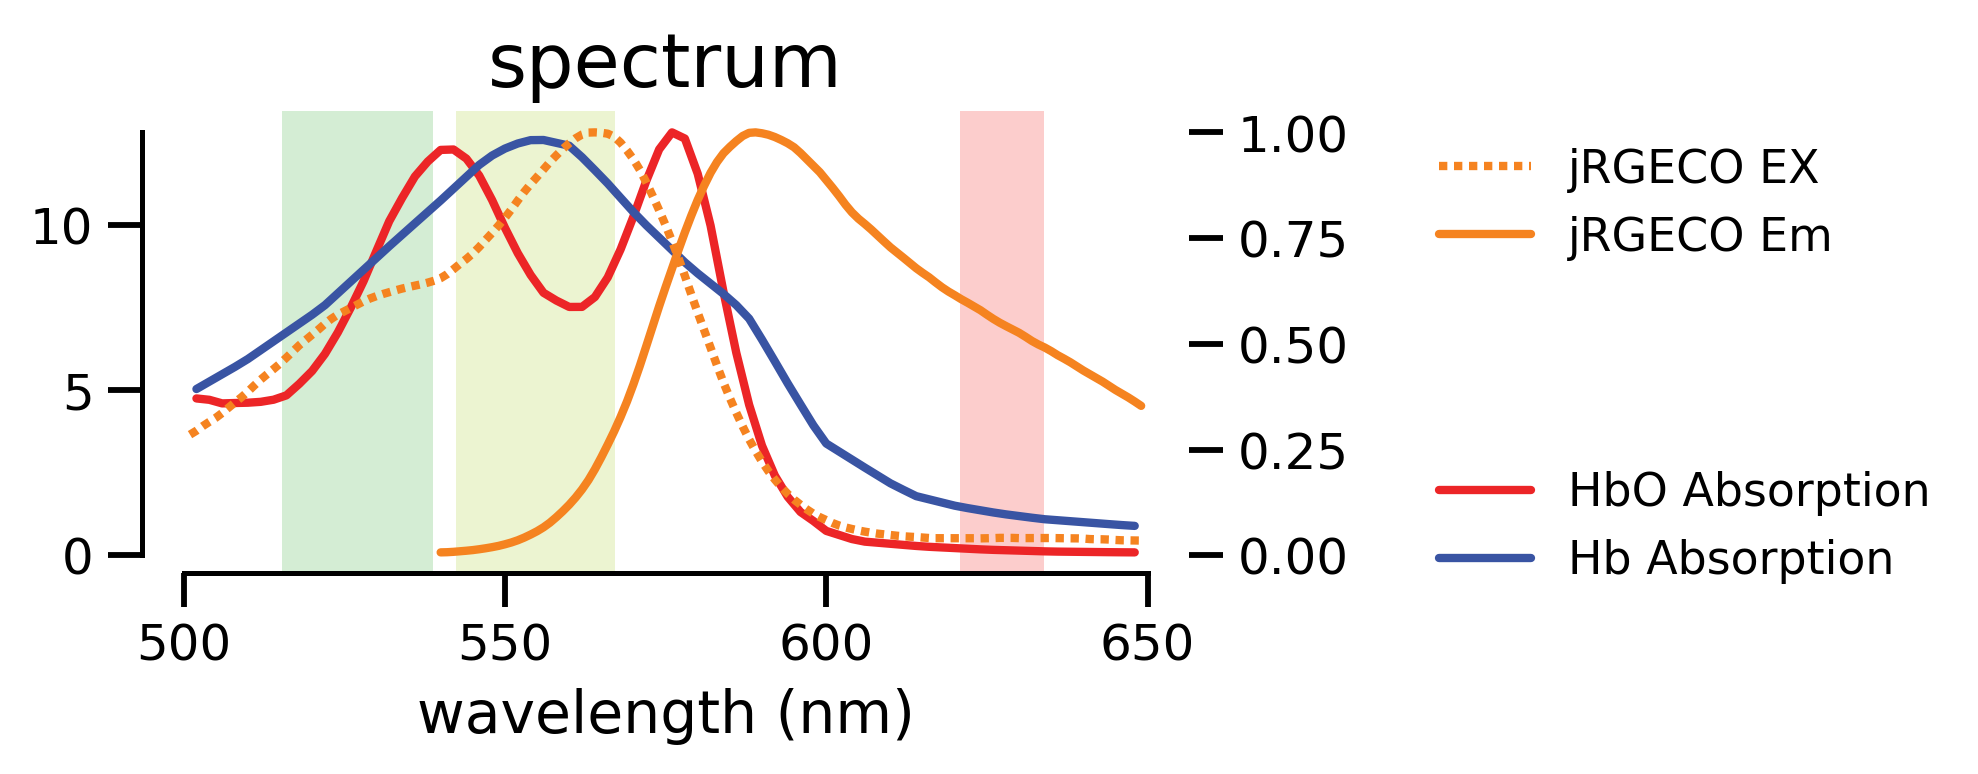

In [22]:
plt.rcParams['svg.fonttype'] = 'none'
with plt.style.context(spstyle.get_style('nature')):
    fig,ax1 = plt.subplots(figsize=(4.5,2))
    
    # which_filter = 'blue_ex'
    # wl_start,wl_stop = find_start_stop_wavelengths(which_filter)
    # ax1.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#abd5ef',alpha=0.5)
    # # ax2.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#abd5ef',alpha=0.5)
        
    which_filter = 'green_ex'
    wl_start,wl_stop = find_start_stop_wavelengths(which_filter)
    ax1.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#aadcab',alpha=0.5)
    # ax2.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#aadcab',alpha=0.5)
              
    which_filter = 'lime_ex'
    wl_start,wl_stop = find_start_stop_wavelengths(which_filter)
    ax1.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#dbeaa5',alpha=0.5)
    # ax2.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#dbeaa5',alpha=0.5)
        
    which_filter = 'red_ex'
    wl_start,wl_stop = find_start_stop_wavelengths(which_filter)
    ax1.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#fa9d9b',alpha=0.5)
    # ax2.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#fa9d9b',alpha=0.5)
                 

    
    ax1.plot(lambdaHb[index_hb],Hb02[index_hb]/1000,label='HbO Absorption',color='#ec2527')
    ax1.plot(lambdaHb[index_hb],Hb[index_hb]/1000,label='Hb Absorption',color='#3954a3')
    
    
    fig, ax1 = sppolish.set_bounds(fig, ax1)
    
    ax2 = ax1.twinx()
    ax2.plot(jrgeco_spec.loc[index_jrgeco,'wavelength'],
             jrgeco_spec.loc[index_jrgeco,'jRGECO1a (calcium saturated) ex'],label='jRGECO EX',color='#f58320',linestyle=(0, (1, 0.8)))
    ax2.plot(jrgeco_spec.loc[index_jrgeco,'wavelength'],
             jrgeco_spec.loc[index_jrgeco,'jRGECO1a (calcium saturated) em'],label='jRGECO Em',color='#f58320')
    # ax2.plot(gcamp_spec.loc[index_gcamp,'wavelength'],
    #          gcamp_spec.loc[index_gcamp,'GCaMP6f (In presence of Ca2+) ex'],label='GCaMP EX',color='#1db14a',linestyle=(0, (1, 0.8)))
    # ax2.plot(gcamp_spec.loc[index_gcamp,'wavelength'],
    #          gcamp_spec.loc[index_gcamp,'GCaMP6f (In presence of Ca2+) em'],label='GCaMP EM',color='#1db14a')

    fig, ax2 = sppolish.set_bounds(fig, ax2)   
    # ax2.plot(range(500,550),1.1*np.ones(550-500),linewidth=5, color='gray')
    # ax2.plot(range(582,636),1.1*np.ones(636-582),linewidth=5, color='gray')
    
    ax1.legend(loc='center left', bbox_to_anchor=(1.2, 0.1))
    ax2.legend(loc='center left', bbox_to_anchor=(1.2, 0.8))
    ax1.locator_params(nbins=5, axis='x')
    ax1.set_xlabel('wavelength (nm)')
    ax1.set_title('spectrum')
#     from matplotlib.legend_handler import HandlerLine2D

#     def update_prop(handle, orig):
#         handle.update_from(orig)
#         x,y = handle.get_data()
#         handle.set_data([np.mean(x)]*2, [0, 2*y[0]])

#     ax1.legend(handler_map={plt.Line2D:HandlerLine2D(update_func=update_prop)},loc='center left', bbox_to_anchor=(1.2, 0.1))
#     ax2.legend(handler_map={plt.Line2D:HandlerLine2D(update_func=update_prop)},loc='center left', bbox_to_anchor=(1.2, 0.8))
    plt.savefig('fig1-spectrum-1.svg',format='svg',dpi=300)
             

# DONE

In [27]:
index_hb = np.logical_and(lambdaHb>500,lambdaHb<650)
index_jrgeco = np.logical_and(jrgeco_spec['wavelength']>500,jrgeco_spec['wavelength']<650)
index_gcamp = np.logical_and(gcamp_spec['wavelength']>500,gcamp_spec['wavelength']<650)
index_filters = np.logical_and(filters_spec['wavelength ']>500,filters_spec['wavelength ']<650)


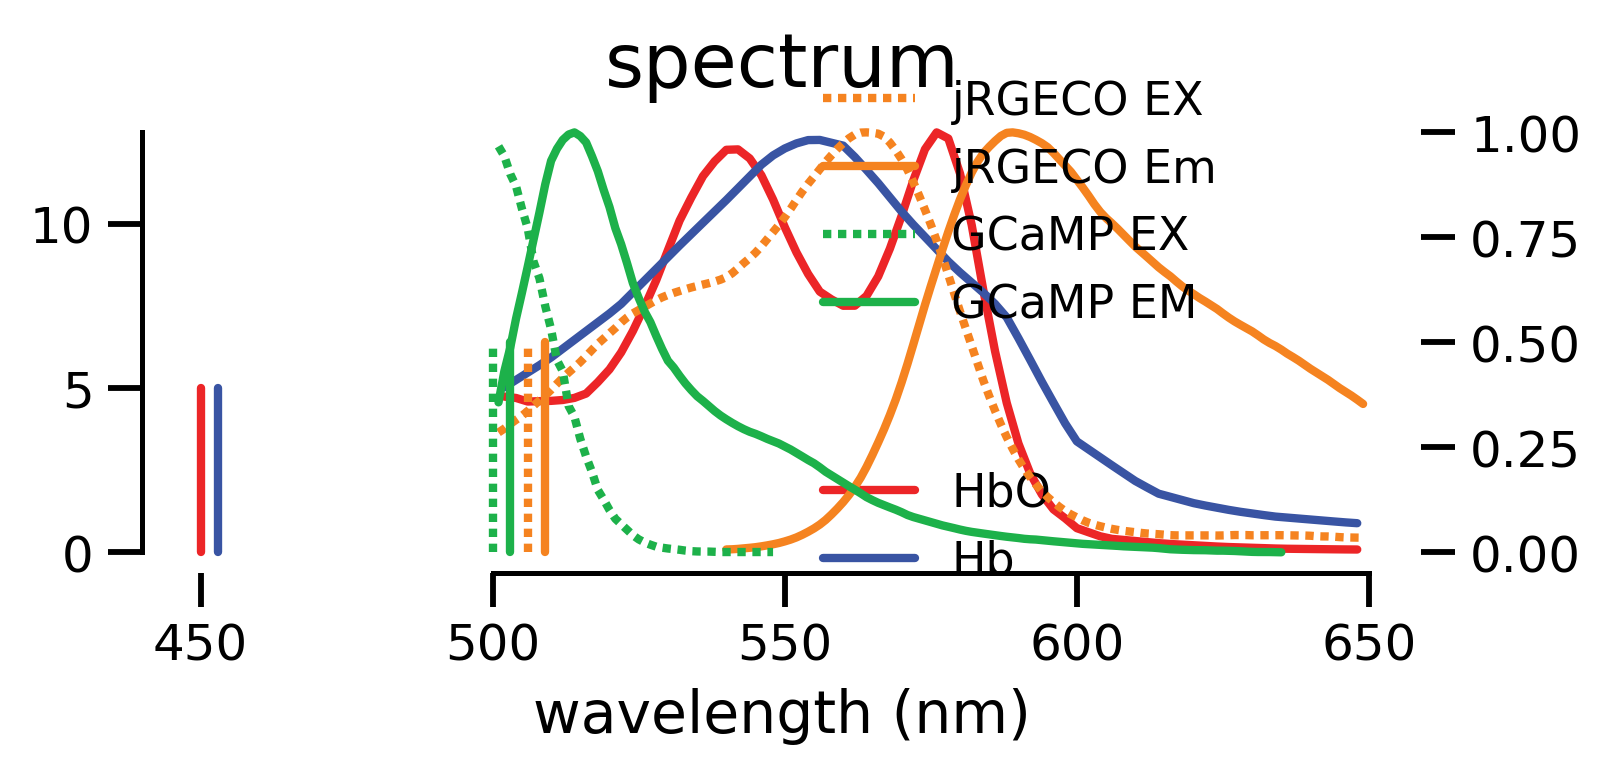

In [23]:
plt.rcParams['svg.fonttype'] = 'none'
with plt.style.context(spstyle.get_style('nature')):
    fig,ax1 = plt.subplots(figsize=(5.5,2))
  
    ax1.plot(lambdaHb[index_hb],Hb02[index_hb]/1000,label='HbO',color='#ec2527')
    ax1.plot(lambdaHb[index_hb],Hb[index_hb]/1000,label='Hb',color='#3954a3')
    
    
    fig, ax1 = sppolish.set_bounds(fig, ax1)
    
    ax2 = ax1.twinx()
    ax2.plot(jrgeco_spec.loc[index_jrgeco,'wavelength'],
             jrgeco_spec.loc[index_jrgeco,'jRGECO1a (calcium saturated) ex'],label='jRGECO EX',color='#f58320',linestyle=(0, (1, 0.8)))
    ax2.plot(jrgeco_spec.loc[index_jrgeco,'wavelength'],
             jrgeco_spec.loc[index_jrgeco,'jRGECO1a (calcium saturated) em'],label='jRGECO Em',color='#f58320')
    ax2.plot(gcamp_spec.loc[index_gcamp,'wavelength'],
             gcamp_spec.loc[index_gcamp,'GCaMP6f (In presence of Ca2+) ex'],label='GCaMP EX',color='#1db14a',linestyle=(0, (1, 0.8)))
    ax2.plot(gcamp_spec.loc[index_gcamp,'wavelength'],
             gcamp_spec.loc[index_gcamp,'GCaMP6f (In presence of Ca2+) em'],label='GCaMP EM',color='#1db14a')

    fig, ax2 = sppolish.set_bounds(fig, ax2)   
    # ax2.plot(range(500,550),1.1*np.ones(550-500),linewidth=5, color='gray')
    # ax2.plot(range(582,636),1.1*np.ones(636-582),linewidth=5, color='gray')
    
    ax1.legend(loc='center left', bbox_to_anchor=(0.5, 0.1))
    ax2.legend(loc='center left', bbox_to_anchor=(0.5, 0.8))
    ax1.locator_params(nbins=5, axis='x')
    ax1.set_xlabel('wavelength (nm)')
    ax1.set_title('spectrum')
    # plt.savefig(save_root+'spectrum-2.svg',format='svg',dpi=300)
    
    ax1.plot(np.ones(6)*450,range(0,6),color='#ec2527')
    ax1.plot(np.ones(6)*453,range(0,6),color='#3954a3')
    
    ax2.plot(np.ones(6)*500,np.linspace(0,0.5,6),color='#1db14a',linestyle=(0, (1, 0.8)))
    ax2.plot(np.ones(6)*503,np.linspace(0,0.5,6),color='#1db14a')
    ax2.plot(np.ones(6)*506,np.linspace(0,0.5,6),color='#f58320',linestyle=(0, (1, 0.8)))
    ax2.plot(np.ones(6)*509,np.linspace(0,0.5,6),color='#f58320')
    plt.savefig('fig1-spectrum-2.svg',format='svg',dpi=300)
             

In [52]:
save_root='/scratch/users/wx2203/new_analysis_locker/pub-locker/acadia-figures/figure1/'


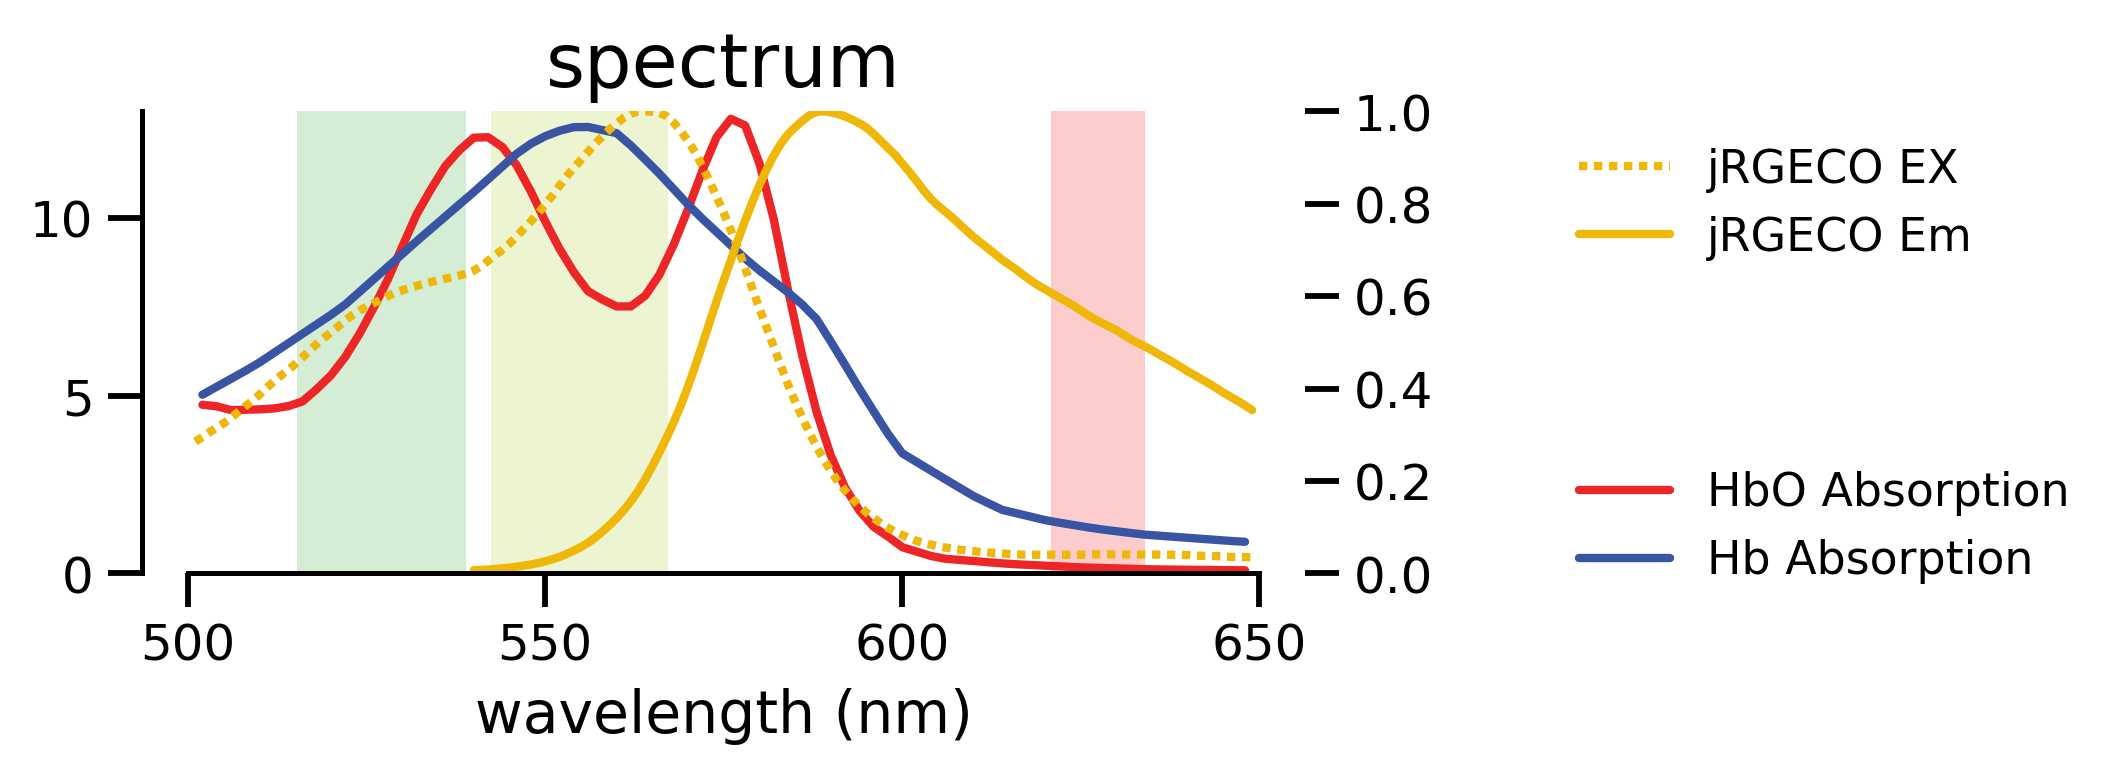

In [53]:
plt.rcParams['svg.fonttype'] = 'none'
with plt.style.context(spstyle.get_style('nature')):
    fig,ax1 = plt.subplots(figsize=(5,2))

    which_filter = 'green_ex'
    wl_start,wl_stop = find_start_stop_wavelengths(which_filter)
    ax1.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#aadcab',alpha=0.5)
    # ax2.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#aadcab',alpha=0.5)
              
    which_filter = 'lime_ex'
    wl_start,wl_stop = find_start_stop_wavelengths(which_filter)
    ax1.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#dbeaa5',alpha=0.5)
    # ax2.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#dbeaa5',alpha=0.5)
        
    which_filter = 'red_ex'
    wl_start,wl_stop = find_start_stop_wavelengths(which_filter)
    ax1.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#fa9d9b',alpha=0.5)
    # ax2.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#fa9d9b',alpha=0.5)
                 

    
    ax1.plot(lambdaHb[index_hb],Hb02[index_hb]/1000,label='HbO Absorption',color='#ec2527')
    ax1.plot(lambdaHb[index_hb],Hb[index_hb]/1000,label='Hb Absorption',color='#3954a3')
    
    
    fig, ax1 = sppolish.set_bounds(fig, ax1)
    
    ax2 = ax1.twinx()
    ax2.plot(jrgeco_spec.loc[index_jrgeco,'wavelength'],
             jrgeco_spec.loc[index_jrgeco,'jRGECO1a (calcium saturated) ex'],label='jRGECO EX',color='#efb708',linestyle=(0, (1, 0.8)))
    ax2.plot(jrgeco_spec.loc[index_jrgeco,'wavelength'],
             jrgeco_spec.loc[index_jrgeco,'jRGECO1a (calcium saturated) em'],label='jRGECO Em',color='#efb708')

    fig, ax2 = sppolish.set_bounds(fig, ax2)   
    # ax2.plot(range(500,550),1.1*np.ones(550-500),linewidth=5, color='gray')
    # ax2.plot(range(582,636),1.1*np.ones(636-582),linewidth=5, color='gray')
    
    ax1.legend(loc='center left', bbox_to_anchor=(1.2, 0.1))
    ax2.legend(loc='center left', bbox_to_anchor=(1.2, 0.8))
    ax1.locator_params(nbins=5, axis='x')
    ax1.set_xlabel('wavelength (nm)')
    ax1.set_title('spectrum')
    ax1.set_ylim([0,13])
    ax2.set_ylim([0,1])
#     from matplotlib.legend_handler import HandlerLine2D

#     def update_prop(handle, orig):
#         handle.update_from(orig)
#         x,y = handle.get_data()
#         handle.set_data([np.mean(x)]*2, [0, 2*y[0]])

#     ax1.legend(handler_map={plt.Line2D:HandlerLine2D(update_func=update_prop)},loc='center left', bbox_to_anchor=(1.2, 0.1))
#     ax2.legend(handler_map={plt.Line2D:HandlerLine2D(update_func=update_prop)},loc='center left', bbox_to_anchor=(1.2, 0.8))
    plt.savefig(save_root+'spectrum-3color-1.svg',format='svg',dpi=300)
             

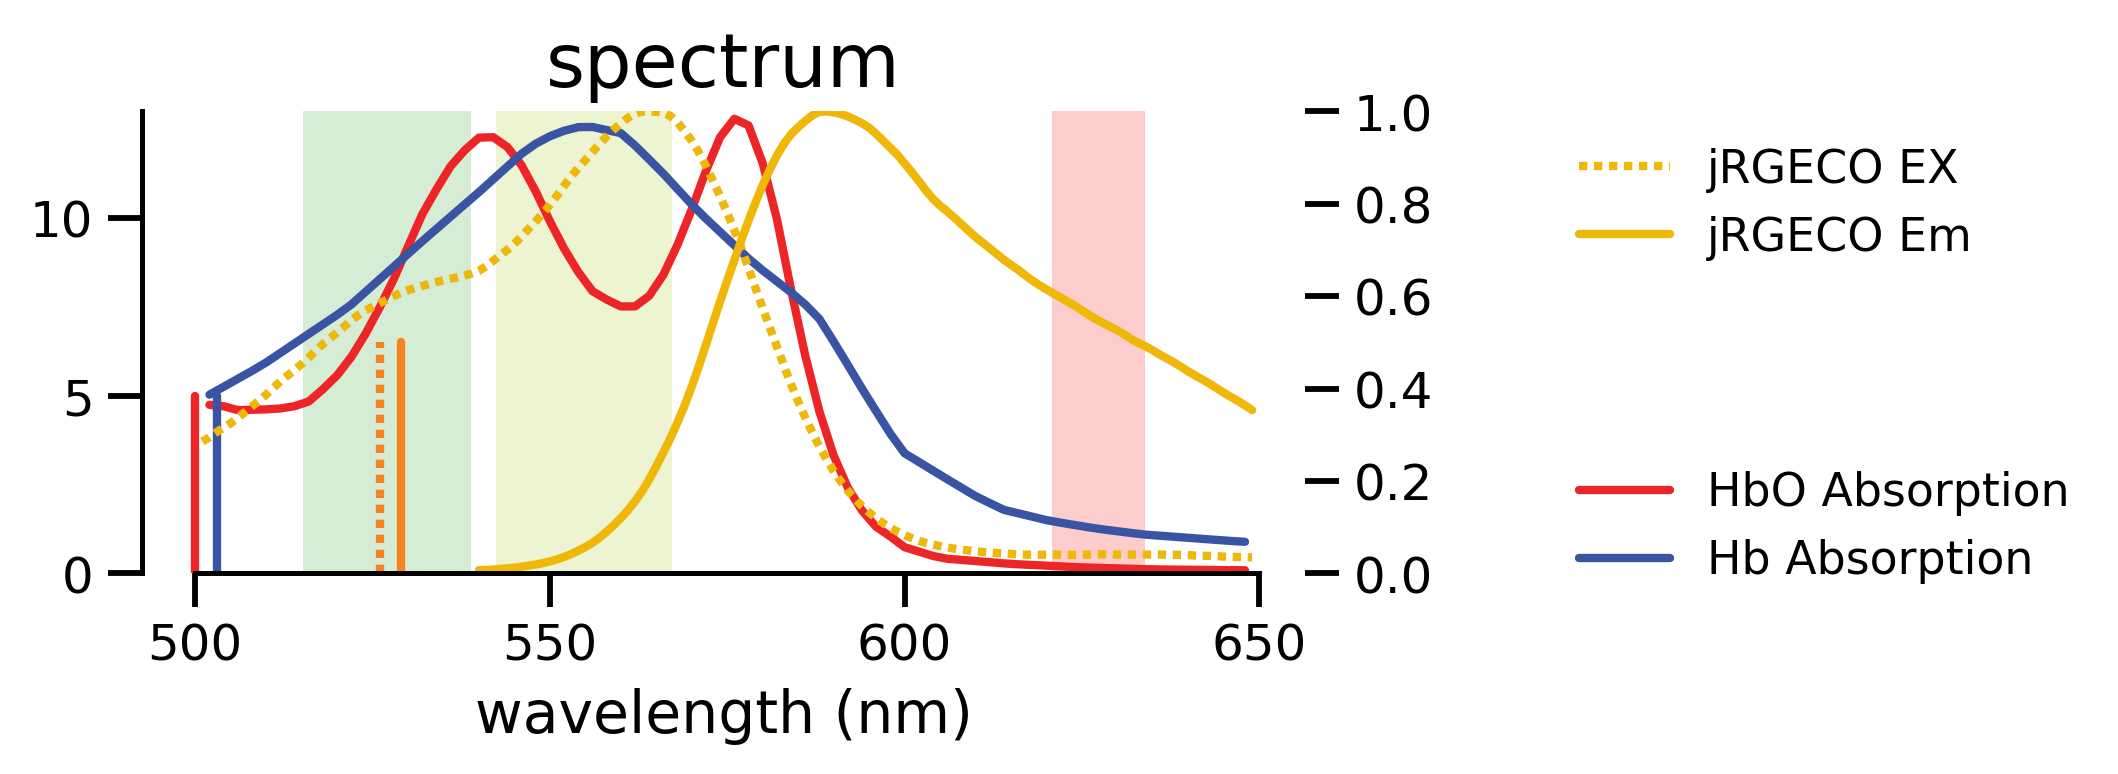

In [54]:
plt.rcParams['svg.fonttype'] = 'none'
with plt.style.context(spstyle.get_style('nature')):
    fig,ax1 = plt.subplots(figsize=(5,2))

    which_filter = 'green_ex'
    wl_start,wl_stop = find_start_stop_wavelengths(which_filter)
    ax1.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#aadcab',alpha=0.5)
    # ax2.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#aadcab',alpha=0.5)
              
    which_filter = 'lime_ex'
    wl_start,wl_stop = find_start_stop_wavelengths(which_filter)
    ax1.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#dbeaa5',alpha=0.5)
    # ax2.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#dbeaa5',alpha=0.5)
        
    which_filter = 'red_ex'
    wl_start,wl_stop = find_start_stop_wavelengths(which_filter)
    ax1.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#fa9d9b',alpha=0.5)
    # ax2.axvspan(wl_start,wl_stop,edgecolor=None,linewidth=0,facecolor='#fa9d9b',alpha=0.5)
                 

    
    ax1.plot(lambdaHb[index_hb],Hb02[index_hb]/1000,label='HbO Absorption',color='#ec2527')
    ax1.plot(lambdaHb[index_hb],Hb[index_hb]/1000,label='Hb Absorption',color='#3954a3')
    
    
    fig, ax1 = sppolish.set_bounds(fig, ax1)
    
    ax2 = ax1.twinx()
    ax2.plot(jrgeco_spec.loc[index_jrgeco,'wavelength'],
             jrgeco_spec.loc[index_jrgeco,'jRGECO1a (calcium saturated) ex'],label='jRGECO EX',color='#efb708',linestyle=(0, (1, 0.8)))
    ax2.plot(jrgeco_spec.loc[index_jrgeco,'wavelength'],
             jrgeco_spec.loc[index_jrgeco,'jRGECO1a (calcium saturated) em'],label='jRGECO Em',color='#efb708')

    fig, ax2 = sppolish.set_bounds(fig, ax2)   
    # ax2.plot(range(500,550),1.1*np.ones(550-500),linewidth=5, color='gray')
    # ax2.plot(range(582,636),1.1*np.ones(636-582),linewidth=5, color='gray')
    
    ax1.legend(loc='center left', bbox_to_anchor=(1.2, 0.1))
    ax2.legend(loc='center left', bbox_to_anchor=(1.2, 0.8))
    ax1.locator_params(nbins=5, axis='x')
    ax1.set_xlabel('wavelength (nm)')
    ax1.set_title('spectrum')
    ax1.set_ylim([0,13])
    ax2.set_ylim([0,1])
#     from matplotlib.legend_handler import HandlerLine2D

#     def update_prop(handle, orig):
#         handle.update_from(orig)
#         x,y = handle.get_data()
#         handle.set_data([np.mean(x)]*2, [0, 2*y[0]])

#     ax1.legend(handler_map={plt.Line2D:HandlerLine2D(update_func=update_prop)},loc='center left', bbox_to_anchor=(1.2, 0.1))
#     ax2.legend(handler_map={plt.Line2D:HandlerLine2D(update_func=update_prop)},loc='center left', bbox_to_anchor=(1.2, 0.8))

    ax1.plot(np.ones(6)*500,range(0,6),color='#ec2527')
    ax1.plot(np.ones(6)*503,range(0,6),color='#3954a3')
    
    # ax2.plot(np.ones(6)*520,np.linspace(0,0.5,6),color='#1db14a',linestyle=(0, (1, 0.8)))
    # ax2.plot(np.ones(6)*523,np.linspace(0,0.5,6),color='#1db14a')
    ax2.plot(np.ones(6)*526,np.linspace(0,0.5,6),color='#f58320',linestyle=(0, (1, 0.8)))
    ax2.plot(np.ones(6)*529,np.linspace(0,0.5,6),color='#f58320')


    plt.savefig(save_root+'spectrum-3color-2.svg',format='svg',dpi=300)
             